**Research objective:** Investigate how GPT-2 processes contextual information and identify whether attention or MLP components causally influence its next-token prediction.

**Model:** GPT-2 using TransformerLens

**Method:** Clean/corrupted prompts, activation patching, and logit-difference recovery

**Investigated layer: Layer 4**

The purpose was to determine whether changing the subject would alter the model's next-token prediction.

**Observation:** GPT-2 changed its preferred prediction from  dog to  cat.

This established that the model's prediction was sensitive to the subject appearing earlier in the context

In [ ]:
!pip install "transformer-lens<4.0"

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 4.4 MB/s eta 0:00:00
  Created wheel for transformers-stream-generator: filename=transformers_stream_generator-0.0.5-py3-none-any.whl size=12526 sha256=1550f4b7b46d0bdbb26d8ed6a3ca85b8b608e4d0109c61bbf055488bcb03b5d7
  Stored in directory: /root/.cache/pip/wheels/f6/6e/1a/710143d0e50e827ae5b60a47a6d43d715cf1c6e35881a05530
Successfully built transformers-stream-generator


In [ ]:
# 1. Load small model (using a smaller model like GPT-2 small for demonstration)

import torch
import torch.nn.functional as F
from transformer_lens import HookedTransformer
device = "cuda" if torch.cuda.is_available() else "cpu"
model = HookedTransformer.from_pretrained("gpt2-medium", device=device)


/tmp/ipykernel_12633/3255083038.py:7: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2-medium", device=device)


config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded pretrained model gpt2-medium into HookedTransformer


In [ ]:
clean_prompt = "My dog is a good"
clean_tokens = model.to_tokens(clean_prompt)
logits, clean_cache = model.run_with_cache(clean_prompt)

# answer token id
correct_token_id = model.to_single_token(' dog')
clean_logit = logits[0, -1, correct_token_id].item()

print(f"Clean Logits: {clean_logit}")

Clean Logits: 13.740533828735352


In [ ]:
corrupted_prompt = "My cat is a good"

corrupt_tokens = model.to_tokens(corrupted_prompt)
corrupted_logits, corrupted_cache = model.run_with_cache(corrupted_prompt)

# answer token id
corrupted_answer = model.to_single_token(' catcher')
corrupted_logit = corrupted_logits[0, -1, corrupted_answer].item()

print(f"Corrupted Logits: {corrupted_logit}")

Corrupted Logits: 9.620450019836426


**This assumes the clean and corrupted prompts are token-aligned and *`correct_token_id`* refers to the target token in both. If the clean and corrupted logits are nearly identical, this normalization becomes unstable.**

In [ ]:

import torch

layer = 4

# Record clean activations from both components.
with torch.no_grad():
    _, clean_cache = model.run_with_cache(clean_tokens)

def patch_component(component):
    hook_name = f"blocks.{layer}.hook_{component}"

    def patch_fn(activation, hook):
        patched = activation.clone()
        patched[:, -1, :] = clean_cache[hook_name][:, -1, :]
        return patched

    with torch.no_grad():
        logits = model.run_with_hooks(
            corrupt_tokens,
            fwd_hooks=[(hook_name, patch_fn)]
        )

    return logits[0, -1, correct_token_id].item()

attention_logit = patch_component("attn_out")
mlp_logit = patch_component("mlp_out")

print("Attention patched logit:", attention_logit)
print("MLP patched logit:", mlp_logit)


Attention patched logit: 13.778900146484375
MLP patched logit: 13.799507141113281


In [ ]:
with torch.no_grad():
    clean_logits = model(clean_tokens)
    corrupt_logits = model(corrupt_tokens)

L_clean = clean_logits[0, -1, correct_token_id].item()
L_corrupt = corrupt_logits[0, -1, correct_token_id].item()

def recovery(patched_logit):
    return (patched_logit - L_corrupt) / (L_clean - L_corrupt)

print("Clean logit:", L_clean)
print("Corrupt logit:", L_corrupt)

print("Attention recovery:", recovery(attention_logit))
print("MLP recovery:", recovery(mlp_logit))


Clean logit: 13.740533828735352
Corrupt logit: 13.792184829711914
Attention recovery: 0.25720088626292464
MLP recovery: -0.14176514032496307


| Measurement | Clean prompt | Corrupted prompt |
| :--- | :--- | :--- |
| **Input** | My dog is a good | My cat is a good |
| **Top prediction** | dog | cat |
| **Top-token logit** | 13.741 | 15.257 |
| **dog logit** | 13.741 | 13.792 |

**What we're testing: Does the `corrupted prompt` meaningfully change the model's predicted next token, or *does it still predict the same answer*?**

In [ ]:

with torch.no_grad():
    clean_logits = model(clean_tokens)
    corrupt_logits = model(corrupt_tokens)

def inspect_prediction(tokens, logits):
    top = logits[0, -1].topk(5)

    print("Prompt:", model.to_string(tokens))
    for token_id, logit in zip(
        top.indices.tolist(),
        top.values.tolist()
    ):
        print(
            repr(model.to_string([token_id])),
            round(logit, 3)
        )

print("CLEAN:")
inspect_prediction(clean_tokens, clean_logits)

print("\nCORRUPTED:")
inspect_prediction(corrupt_tokens, corrupt_logits)


CLEAN:
Prompt: ['<|endoftext|>My dog is a good']
' dog' 13.741
' friend' 13.68
' boy' 13.433
' example' 13.3
' guy' 13.219

CORRUPTED:
Prompt: ['<|endoftext|>My cat is a good']
' cat' 15.257
' friend' 14.788
' guy' 13.829
' dog' 13.792
' boy' 13.645


### Measuring the Logit Difference

$$
D = \operatorname{logit}(\text{dog}) - \operatorname{logit}(\text{cat})
$$

- Positive $D$: the model prefers **dog** over **cat** ($D > 0$).
- Negative $D$: the model prefers **cat** over **dog** ($D < 0$).

In [ ]:

import torch

dog_id = model.to_single_token(" dog")
cat_id = model.to_single_token(" cat")

def logit_diff(logits):
    return (
        logits[0, -1, dog_id] -
        logits[0, -1, cat_id]
    ).item()

with torch.no_grad():
    clean_logits = model(clean_tokens)
    corrupt_logits = model(corrupt_tokens)

D_clean = logit_diff(clean_logits)
D_corrupt = logit_diff(corrupt_logits)

print("Clean logit difference:", D_clean)
print("Corrupted logit difference:", D_corrupt)

def normalized_recovery(patched_logits):
    D_patched = logit_diff(patched_logits)
    return (
        (D_patched - D_corrupt) /
        (D_clean - D_corrupt)
    )

for component in ["attn_out", "mlp_out"]:
    hook_name = f"blocks.{layer}.hook_{component}"

    def patch_fn(activation, hook):
        patched = activation.clone()
        patched[:, -1, :] = clean_cache[hook_name][:, -1, :]
        return patched

    with torch.no_grad():
        patched_logits = model.run_with_hooks(
            corrupt_tokens,
            fwd_hooks=[(hook_name, patch_fn)]
        )

    print(
        component,
        "recovery:",
        normalized_recovery(patched_logits)
    )


Clean logit difference: 2.4503173828125
Corrupted logit difference: -1.4650163650512695
attn_out recovery: 0.01656523830691568
mlp_out recovery: 0.005875253469410124


### Visualizing Causal Component Recovery
Let's plot the logit difference recovery results for Layer 4 Attention (`attn_out`) and MLP (`mlp_out`) components to clearly compare their causal influence.

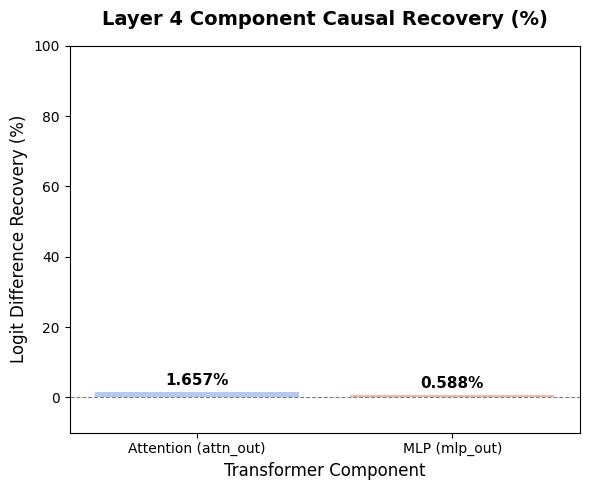

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data from the experiment
components = ['Attention (attn_out)', 'MLP (mlp_out)']
# Store recovery values as percentages
recovery_values = [0.016565 * 100, 0.005875 * 100]

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=components, y=recovery_values, palette='coolwarm', hue=components, legend=False, ax=ax)

# Formatting plot
ax.set_title('Layer 4 Component Causal Recovery (%)', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Logit Difference Recovery (%)', fontsize=12)
ax.set_xlabel('Transformer Component', fontsize=12)
ax.set_ylim(-10, 100)  # Set limit showing up to 100% recovery for perspective
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

# Adding values on top of bars
for i, val in enumerate(recovery_values):
    ax.text(i, val + 2 if val >= 0 else val - 5, f"{val:.3f}%", ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()